<a href="https://colab.research.google.com/github/kfartem434-png/MN_Kapusta/blob/main/%D0%9B%D0%B5%D0%BA%D1%86%D1%96%D1%8F_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D0%B8%D1%85_%D1%80%D1%8F%D0%B4%D1%96%D0%B2_%D0%9A%D0%B0%D0%BF%D1%83%D1%81%D1%82%D0%B0_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практикум: аналіз і прогнозування часових рядів

Цей notebook доповнює лекцію **«Аналіз і прогнозування часових рядів. Навчання та оцінка моделі»**.

Мета практикуму — послідовно пройти основні етапи прогнозування:

1. підготовка часових даних;
2. візуальний аналіз;
3. дослідження тренду та сезонності;
4. коректний часовий поділ на train/test;
5. побудова базових прогнозів;
6. оцінювання якості за MAE, RMSE, sMAPE та MASE;
7. застосування ETS;
8. застосування SARIMA;
9. використання Prophet;
10. побудова ML-моделі на лагових і календарних ознаках;
11. покрокова ретроспективна перевірка;
12. самостійні завдання.

**Важливо:** у часових рядах не можна випадково перемішувати спостереження перед поділом на навчальну і тестову вибірки.

## 1. Підключення бібліотек

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 50)
np.random.seed(42)

## 2. Формування навчального часового ряду

Щоб notebook можна було виконувати без завантаження зовнішніх файлів, використаємо штучно сформований щоденний ряд продажів. Він містить:

- довгостроковий тренд;
- тижневу сезонність;
- річну сезонність;
- підвищення попиту у вихідні;
- випадковий шум;
- декілька аномальних значень.

Такий ряд зручний для демонстрації основних етапів forecasting.

In [4]:
dates = pd.date_range("2022-01-01", "2025-12-31", freq="D")
n = len(dates)
t = np.arange(n)

trend = 100 + 0.035 * t
weekly = 12 * np.sin(2 * np.pi * t / 7)
yearly = 8 * np.sin(2 * np.pi * t / 365.25)
weekend = np.where(dates.dayofweek >= 5, 10, 0)
noise = np.random.normal(0, 6, n)

sales = trend + weekly + yearly + weekend + noise

df = pd.DataFrame({
    "date": dates,
    "sales": sales
})

# Додаємо кілька пропусків та аномалій для демонстрації підготовки даних
missing_idx = [120, 450, 900]
outlier_idx = [300, 700, 1100]

df.loc[missing_idx, "sales"] = np.nan
df.loc[outlier_idx, "sales"] *= 1.7

df.head()

,date,sales
0,2022-01-01,112.980285
1,2022-01-02,118.725005
2,2022-01-03,115.930451
3,2022-01-04,114.862459
4,2022-01-05,94.078518


In [5]:
print(df.shape)
print(df.dtypes)
print("\nКількість пропусків:")
print(df.isna().sum())

(1461, 2)
date     datetime64[ns]
sales           float64
dtype: object

Кількість пропусків:
date     0
sales    3
dtype: int64


### Завдання 1. Первинний аналіз

1. Виведіть останні 10 рядків.
2. Визначте мінімальну та максимальну дату.
3. Обчисліть середнє, медіану, стандартне відхилення, мінімум і максимум `sales`.
4. Перевірте, чи є дублікати дат.

In [6]:
# Ваш код тут
display(df.tail(10))

print("Мінімальна дата:",df["date"].min(),"Максимальна дата:",df["date"].max())
print()

print("Середнє:",df["sales"].mean())
print("Медіана:",df["sales"].median())
print("стандартне відхилення:",df["sales"].std())
print("мінімум:",df["sales"].min())
print("максимум:",df["sales"].max())
print()

print("Кількість дублікатів дат:",df["date"].duplicated().sum())

,date,sales
1451,2025-12-22,171.328008
1452,2025-12-23,156.237492
1453,2025-12-24,160.161011
1454,2025-12-25,141.622914
1455,2025-12-26,130.154195
1456,2025-12-27,164.792801
1457,2025-12-28,172.113885
1458,2025-12-29,170.054977
1459,2025-12-30,160.035508
1460,2025-12-31,144.925047


Мінімальна дата: 2022-01-01 00:00:00 Максимальна дата: 2025-12-31 00:00:00

Середнє: 128.86840539993554
Медіана: 128.30740465635068
стандартне відхилення: 19.969577035218677
мінімум: 78.05403090053971
максимум: 279.5724799225864

Кількість дублікатів дат: 0


## 3. Підготовка часових даних

Для подальшого аналізу необхідно:

- перетворити дату у формат `datetime`;
- відсортувати дані;
- зробити дату індексом;
- перевірити регулярність часового кроку;
- обробити пропущені значення.

У цьому прикладі пропуски заповнюються часовою інтерполяцією.

In [7]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates(subset="date")
df = df.set_index("date")

print(pd.infer_freq(df.index))

df["sales"] = df["sales"].interpolate(method="time")

print("Пропусків після інтерполяції:", df["sales"].isna().sum())
df.head()

D
Пропусків після інтерполяції: 0


,sales
date,
2022-01-01,112.980285
2022-01-02,118.725005
2022-01-03,115.930451
2022-01-04,114.862459
2022-01-05,94.078518


### Завдання 2. Робота з пропусками

Створіть копію набору даних `df_task` і штучно видаліть значення `sales` для п'яти довільних дат.

Порівняйте три способи заповнення:

- `ffill`;
- лінійну інтерполяцію;
- часову інтерполяцію.

Коротко поясніть, який спосіб доцільніший для цього ряду.

In [8]:
# Ваш код тут
df_task = df.copy()
rng = np.random.default_rng(42)
delete_idx = rng.choice(df.index,size=5)
df_task.loc[delete_idx, "sales"] = np.nan

display(df_task.loc[delete_idx])

df_task.loc[delete_idx, "sales"] = np.nan
df_task["sales"] = df_task["sales"].ffill()

display(df_task.loc[delete_idx])

df_task.loc[delete_idx, "sales"] = np.nan
df_task["sales"] = df_task["sales"].interpolate()

display(df_task.loc[delete_idx])

df_task.loc[delete_idx, "sales"] = np.nan
df_task["sales"] = df_task["sales"].interpolate(method="time")

display(df_task.loc[delete_idx])

,sales
date,
2022-05-11,NaN
2025-02-04,NaN
2024-08-14,NaN
2023-10-04,NaN
2023-09-25,NaN


,sales
date,
2022-05-11,113.077564
2025-02-04,157.517097
2024-08-14,140.058189
2023-10-04,117.592678
2023-09-25,142.723498


,sales
date,
2022-05-11,106.290838
2025-02-04,149.493113
2024-08-14,129.556842
2023-10-04,109.407678
2023-09-25,129.784546


,sales
date,
2022-05-11,106.290838
2025-02-04,149.493113
2024-08-14,129.556842
2023-10-04,109.407678
2023-09-25,129.784546


## 4. Візуальний аналіз

Графік часового ряду є першим інструментом діагностики. За ним оцінюють:

- загальний напрям зміни;
- сезонні коливання;
- можливі структурні зміни;
- викиди;
- зміну дисперсії.

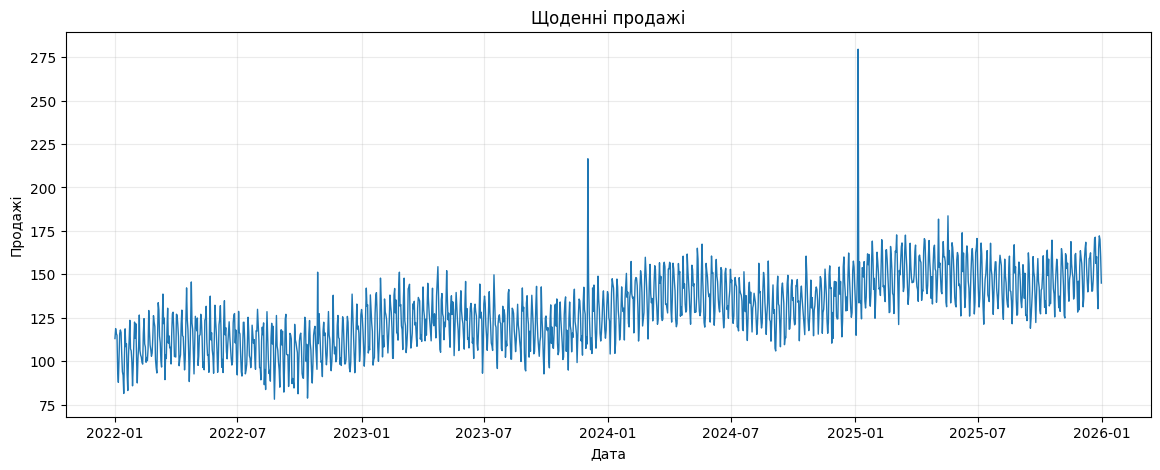

In [9]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["sales"], linewidth=1)
ax.set_title("Щоденні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.grid(alpha=0.25)
plt.show()

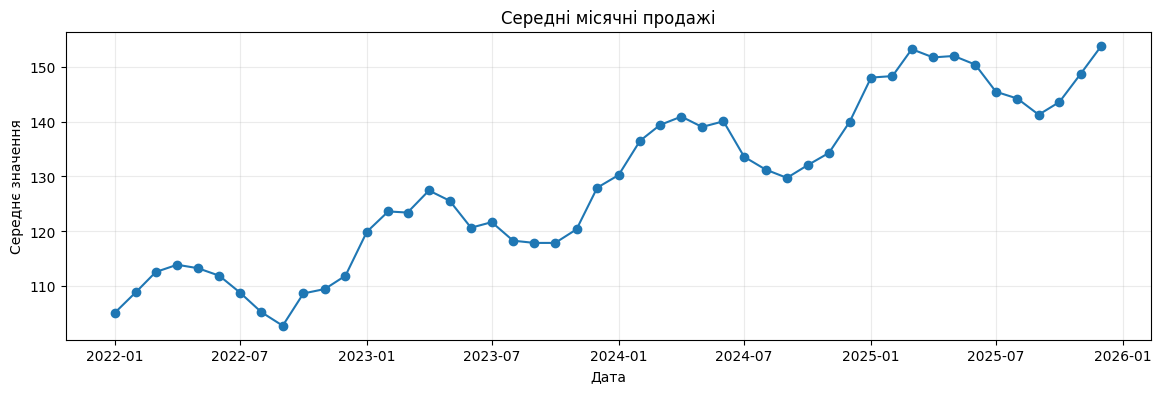

In [10]:
monthly = df["sales"].resample("MS").mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_title("Середні місячні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Середнє значення")
ax.grid(alpha=0.25)
plt.show()

### Завдання 3. Візуалізація

1. Побудуйте графік останніх 90 днів.
2. Побудуйте 7-денне та 30-денне ковзні середні.
3. Поясніть, чим відрізняється інформація на цих двох графіках.

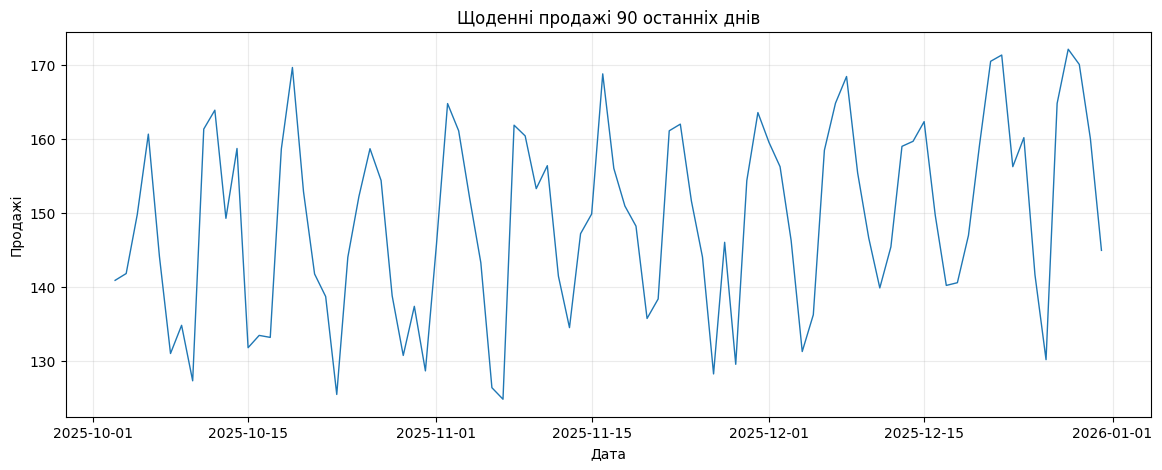

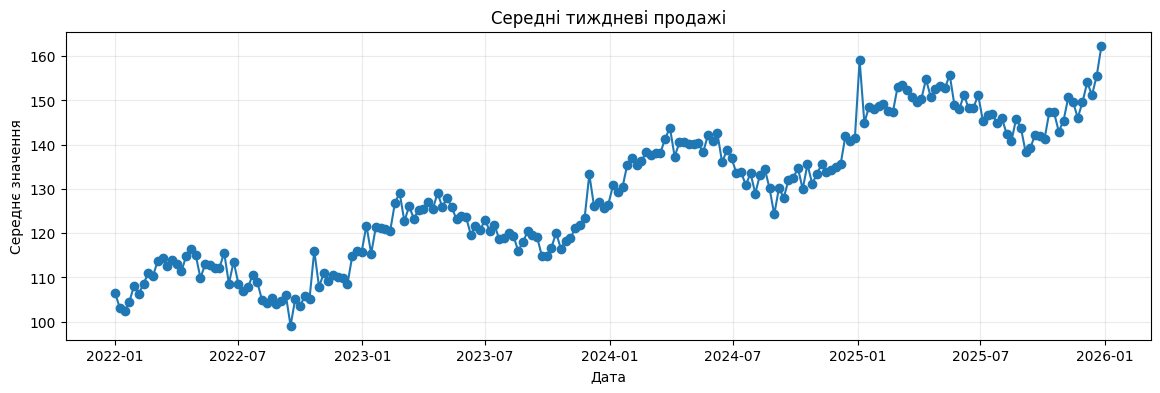

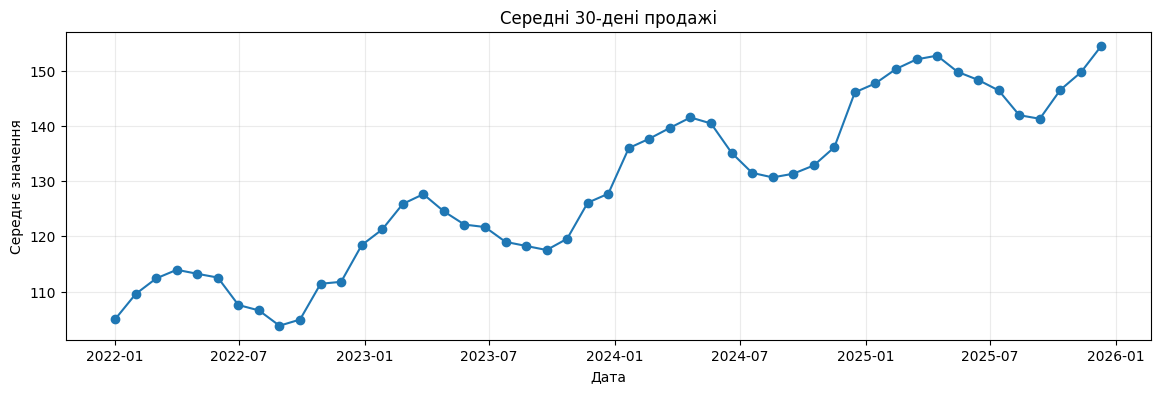

In [11]:
# Ваш код тут
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index[-90:], df["sales"].tail(90), linewidth=1)
ax.set_title("Щоденні продажі 90 останніх днів")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.grid(alpha=0.25)
plt.show()

weekly = df["sales"].resample("7D").mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(weekly.index, weekly.values, marker="o")
ax.set_title("Середні тиждневі продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Середнє значення")
ax.grid(alpha=0.25)
plt.show()

daily30 = df["sales"].resample("30D").mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily30.index, daily30.values, marker="o")
ax.set_title("Середні 30-дені продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Середнє значення")
ax.grid(alpha=0.25)
plt.show()

Графік тиждневих середніх продажів має більш плотні ковзні середні в порівняні з графіком 30-денних продажів.

## 5. Декомпозиція ряду методом STL

STL-декомпозиція розкладає часовий ряд на:

- **trend** — довгострокову тенденцію;
- **seasonal** — сезонну складову;
- **resid** — залишкову складову.

Для щоденних даних з тижневою сезонністю використаємо `period=7`.

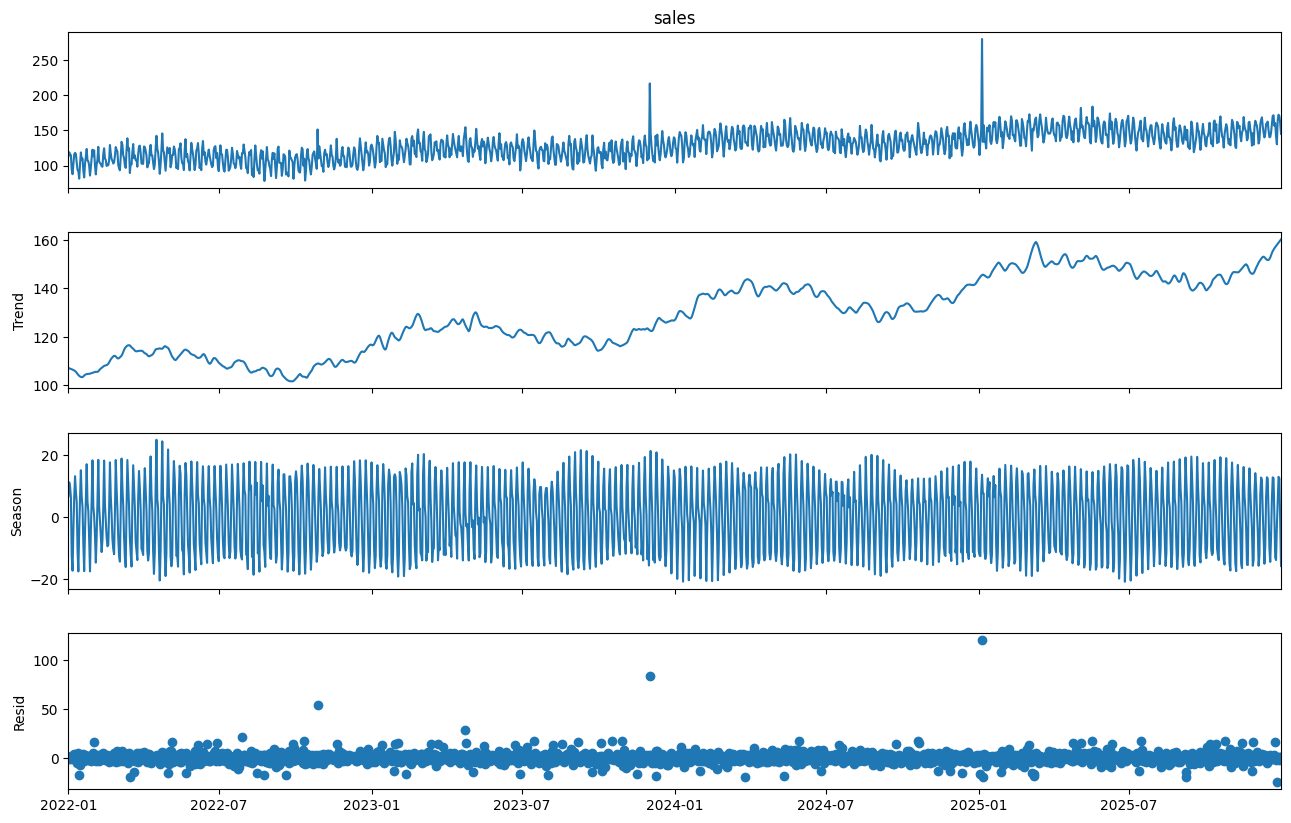

In [12]:
stl = STL(df["sales"], period=7, robust=True)
stl_result = stl.fit()

fig = stl_result.plot()
fig.set_size_inches(14, 9)
plt.show()

### Завдання 4. Декомпозиція

1. Повторіть STL-декомпозицію для місячного ряду.
2. Оберіть обґрунтований період сезонності.
3. Проаналізуйте тренд та залишки.

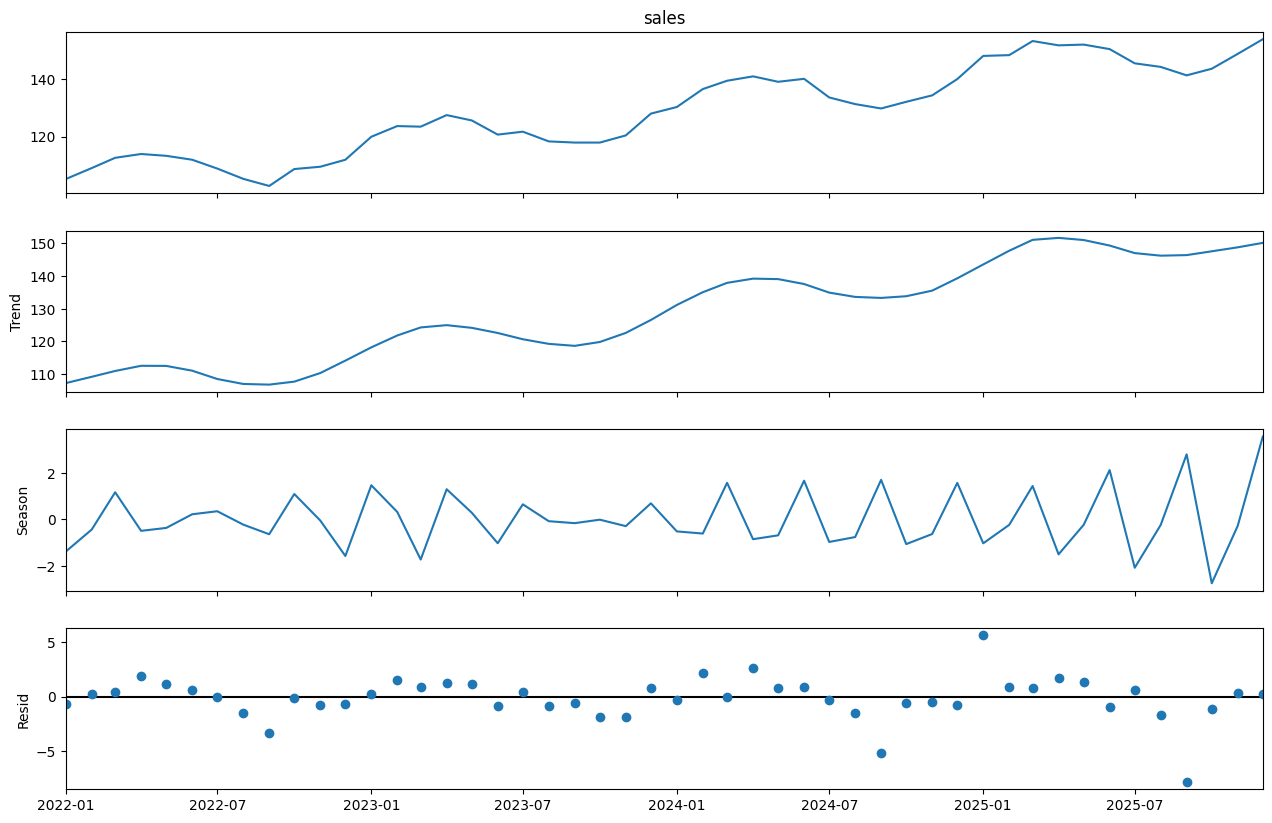

In [13]:
# Ваш код тут
stl_task = STL(df["sales"].resample("MS").mean(),period=3,robust=True)
stl_task_result = stl_task.fit()

fig = stl_task_result.plot()
fig.set_size_inches(14, 9)
plt.show()

## 6. Часовий поділ train/test

У звичайних задачах машинного навчання дані часто перемішують. Для часових рядів це зазвичай неприпустимо.

Нехай останні 90 днів становлять тестовий період. Усі попередні спостереження використовуються для навчання.

In [14]:
horizon = 90

train = df.iloc[:-horizon].copy()
test = df.iloc[-horizon:].copy()

print("Train:", train.index.min().date(), "—", train.index.max().date(), len(train))
print("Test :", test.index.min().date(), "—", test.index.max().date(), len(test))

Train: 2022-01-01 — 2025-10-02 1371
Test : 2025-10-03 — 2025-12-31 90


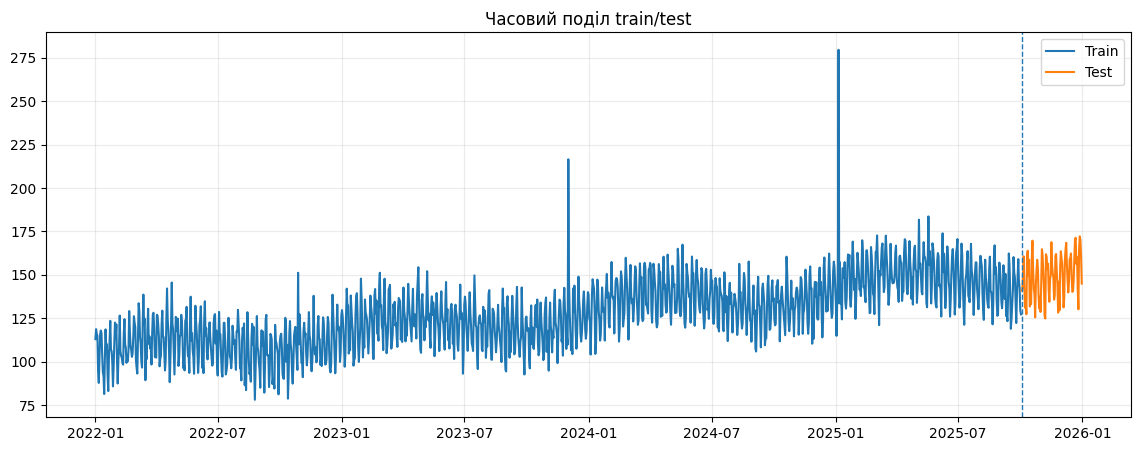

In [15]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train["sales"], label="Train")
ax.plot(test.index, test["sales"], label="Test")
ax.axvline(test.index.min(), linestyle="--", linewidth=1)
ax.legend()
ax.set_title("Часовий поділ train/test")
ax.grid(alpha=0.25)
plt.show()

### Завдання 5. Часовий поділ

Створіть інший варіант поділу, у якому тестовий період дорівнює 60 дням.

Виведіть:

- кількість спостережень у train;
- кількість спостережень у test;
- останню дату train;
- першу дату test.

In [16]:
# Ваш код тут

horizon_task = 60

train_task = df.iloc[:-horizon_task].copy()
test_task = df.iloc[-horizon_task:].copy()

print("Кількість спостережень у train:",len(train_task),"Кількість спостережень у test:",len(test_task))
print("Остання дата train:",train_task.index.max().date(),"Перша дата test:",test_task.index.min().date())

Кількість спостережень у train: 1401 Кількість спостережень у test: 60
Остання дата train: 2025-11-01 Перша дата test: 2025-11-02


## 7. Базові моделі прогнозування

Перед використанням складної моделі потрібно побудувати простий базовий прогноз.

### Naive forecast
Прогноз дорівнює останньому відомому значенню.

### Seasonal naive
Прогноз повторює значення попереднього сезонного циклу. Для щоденних даних з тижневою сезонністю використаємо лаг 7.

In [17]:
naive_pred = np.repeat(train["sales"].iloc[-1], len(test))

history = pd.concat([train["sales"], test["sales"]])
seasonal_naive_pred = history.shift(7).loc[test.index].values

baseline = pd.DataFrame({
    "actual": test["sales"].values,
    "naive": naive_pred,
    "seasonal_naive": seasonal_naive_pred
}, index=test.index)

baseline.head()

,actual,naive,seasonal_naive
date,,,
2025-10-03,140.875312,127.213304,137.575710
2025-10-04,141.794922,127.213304,148.849817
2025-10-05,149.768594,127.213304,159.044241
2025-10-06,160.638161,127.213304,145.953075
2025-10-07,144.109047,127.213304,142.430282


## 8. Метрики якості прогнозу

Використаємо:

- **MAE** — середню абсолютну помилку;
- **RMSE** — квадратний корінь із середньоквадратичної помилки;
- **sMAPE** — симетричну відносну помилку;
- **MASE** — масштабовану абсолютну помилку.

Менше значення метрики зазвичай означає кращий прогноз.

In [18]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def smape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    denom = (np.abs(y_true) + np.abs(y_pred))
    mask = denom != 0
    return 100 * np.mean(
        2 * np.abs(y_pred[mask] - y_true[mask]) / denom[mask]
    )

def mase(y_true, y_pred, y_train, seasonality=1):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_train = np.asarray(y_train)

    scale = np.mean(
        np.abs(y_train[seasonality:] - y_train[:-seasonality])
    )
    return np.mean(np.abs(y_true - y_pred)) / scale

def evaluate(y_true, y_pred, y_train, seasonality=7):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "sMAPE_%": smape(y_true, y_pred),
        "MASE": mase(y_true, y_pred, y_train, seasonality)
    }

results = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7)
}).T

results

,MAE,RMSE,sMAPE_%,MASE
Naive,22.039691,25.297086,15.570350,3.108885
Seasonal naive,7.734062,9.380056,5.276847,1.090955


### Завдання 6. Метрики

1. Визначте, яка базова модель є кращою.
2. Поясніть, чому висновок не слід робити лише за однією метрикою.
3. Обчисліть MAE окремо для перших і останніх 30 днів тестового періоду.

In [19]:
# Ваш код тут

print("MAE naive перші 30:",mean_absolute_error(test["sales"].head(30).values,naive_pred[:30]))
print("MAE naive останні 30:",mean_absolute_error(test["sales"].tail(30).values,naive_pred[-30:]))

print("MAE naive seasonal перші 30:",mean_absolute_error(test["sales"].head(30).values,seasonal_naive_pred[:30]))
print("MAE naive seasonal останні 30:",mean_absolute_error(test["sales"].tail(30).values,seasonal_naive_pred[-30:]))

MAE naive перші 30: 17.549925396832194
MAE naive останні 30: 26.400533286218042
MAE naive seasonal перші 30: 8.15544519336499
MAE naive seasonal останні 30: 6.76778499215381


Модель seasonal naive є кращою. Вона має менші показники у всіх метриках, але у метриці MASE naive та naive seasonal мають достатньо близькі результати, що слідчить про необхіднсть використання декількох метрик для визначення найкращої моделі.

## 9. Експоненційне згладжування ETS

Моделі ETS описують часовий ряд через рівень, тренд і сезонність.

Для навчального прикладу використаємо:

- адитивний тренд;
- адитивну сезонність;
- сезонний період 7 днів.

In [20]:
ets_model = ExponentialSmoothing(
    train["sales"],
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_pred = ets_model.forecast(len(test))

ets_metrics = evaluate(
    test["sales"],
    ets_pred,
    train["sales"],
    seasonality=7
)

ets_metrics

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


{'MAE': 13.11452610803631,
 'RMSE': np.float64(15.229020700077848),
 'sMAPE_%': np.float64(9.14961742586639),
 'MASE': np.float64(1.8499146745742305)}

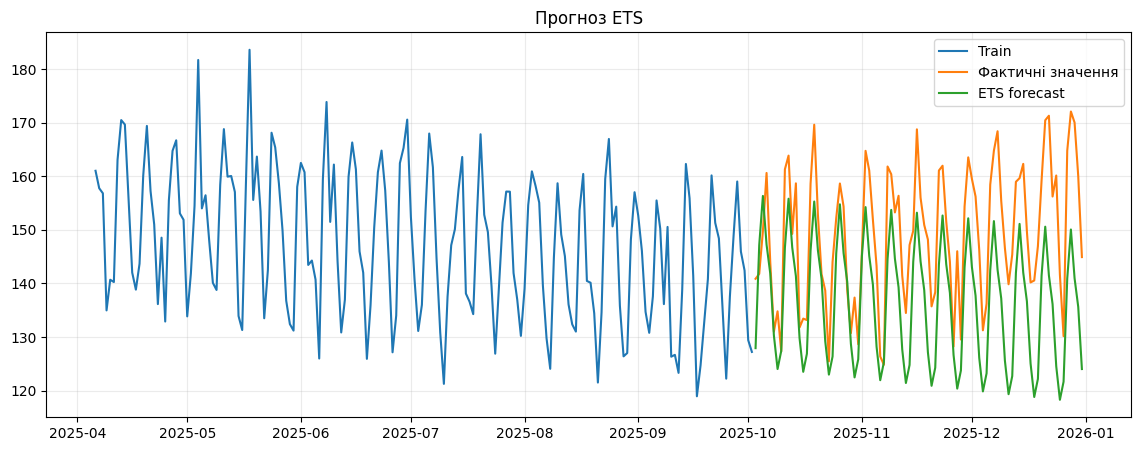

In [21]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-180:], train["sales"].iloc[-180:], label="Train")
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, ets_pred, label="ETS forecast")
ax.legend()
ax.set_title("Прогноз ETS")
ax.grid(alpha=0.25)
plt.show()

### Завдання 7. ETS

1. Побудуйте ETS-модель без тренду.
2. Порівняйте її з поточною моделлю.
3. Додайте результати обох ETS-моделей до таблиці метрик.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


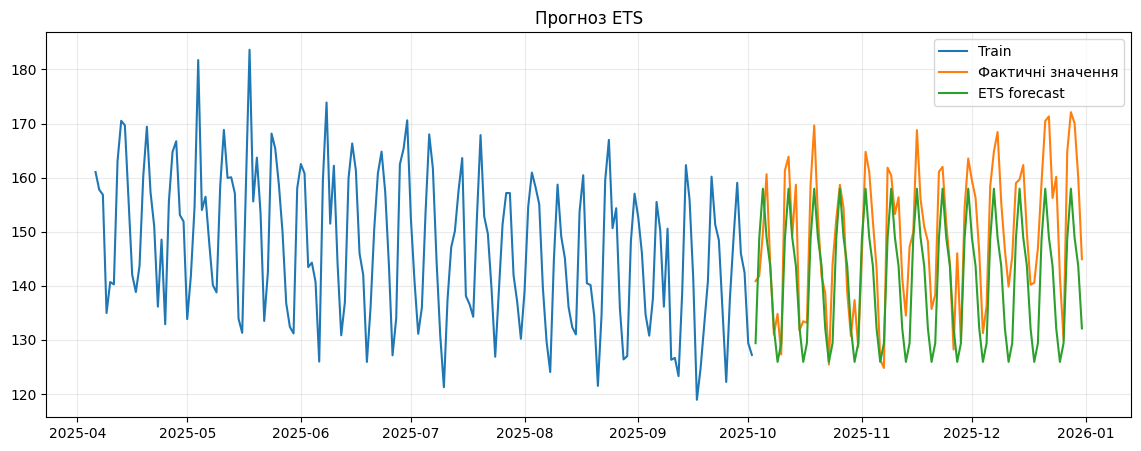

In [22]:
# Ваш код тут
ets_model_task = ExponentialSmoothing(
    train["sales"],
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_pred_task = ets_model_task.forecast(len(test))

ets_metrics_task = evaluate(
    test["sales"],
    ets_pred_task,
    train["sales"],
    seasonality=7
)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-180:], train["sales"].iloc[-180:], label="Train")
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, ets_pred_task, label="ETS forecast")
ax.legend()
ax.set_title("Прогноз ETS")
ax.grid(alpha=0.25)
plt.show()

In [23]:
results2 = pd.concat([results,pd.DataFrame([ets_metrics,ets_metrics_task],index=["ETS","ETS w/o trend"])])
results2

,MAE,RMSE,sMAPE_%,MASE
Naive,22.039691,25.297086,15.570350,3.108885
Seasonal naive,7.734062,9.380056,5.276847,1.090955
ETS,13.114526,15.229021,9.149617,1.849915
ETS w/o trend,8.894899,10.703167,6.091459,1.254701


## 10. SARIMA

SARIMA розширює ARIMA сезонними компонентами.

У загальному випадку модель записують як:

**SARIMA(p, d, q)(P, D, Q, s)**,

де `s` — довжина сезонного циклу.

Нижче використано невелику модель, щоб приклад виконувався відносно швидко.

In [24]:
sarima_model = SARIMAX(
    train["sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_forecast = sarima_model.get_forecast(steps=len(test))
sarima_pred = sarima_forecast.predicted_mean
sarima_ci = sarima_forecast.conf_int()

sarima_metrics = evaluate(
    test["sales"],
    sarima_pred,
    train["sales"],
    seasonality=7
)

sarima_metrics

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


{'MAE': 7.7465658208202095,
 'RMSE': np.float64(9.401756189500011),
 'sMAPE_%': np.float64(5.302245527656123),
 'MASE': np.float64(1.0927185375542505)}

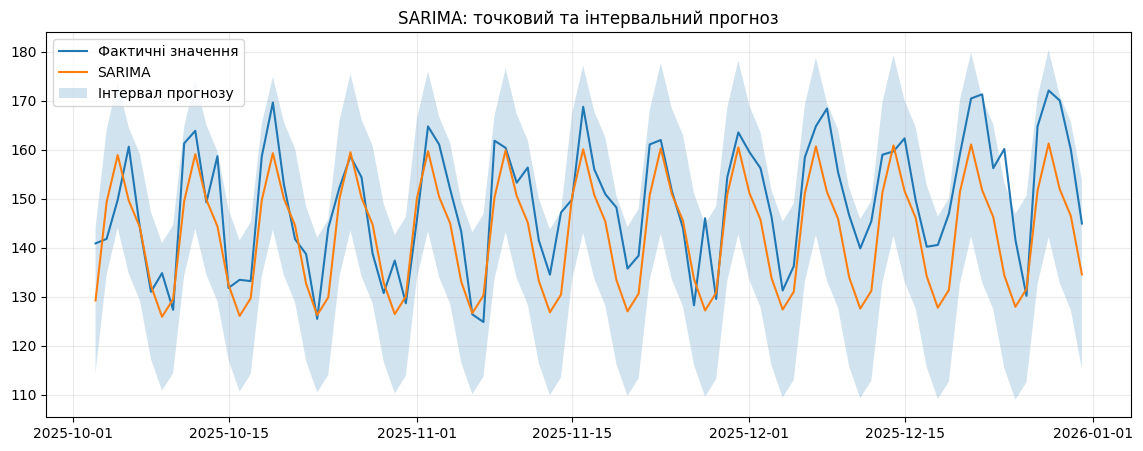

In [25]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, sarima_pred, label="SARIMA")
ax.fill_between(
    test.index,
    sarima_ci.iloc[:, 0].values,
    sarima_ci.iloc[:, 1].values,
    alpha=0.2,
    label="Інтервал прогнозу"
)
ax.legend()
ax.set_title("SARIMA: точковий та інтервальний прогноз")
ax.grid(alpha=0.25)
plt.show()

### Завдання 8. SARIMA

Змініть параметри моделі, наприклад:

- `order=(2, 1, 1)`;
- `seasonal_order=(1, 1, 0, 7)`.

Порівняйте MAE та RMSE з попередньою SARIMA-моделлю.

**Примітка:** мета завдання — зрозуміти вплив параметрів, а не виконати повний автоматичний підбір.

In [26]:
# Ваш код тут
sarima_model_task = SARIMAX(
  train["sales"],
  order=(2, 1, 1),
  seasonal_order=(1, 1, 0, 7),
  enforce_stationarity=False,
  enforce_invertibility=False
).fit(disp=False)

sarima_forecast_task = sarima_model_task.get_forecast(steps=len(test))
sarima_pred_task = sarima_forecast_task.predicted_mean
sarima_ci_task = sarima_forecast_task.conf_int()

sarima_metrics_task = evaluate(
  test["sales"],
  sarima_pred_task,
  train["sales"],
  seasonality=7
)

sarima_metrics_task

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


{'MAE': 8.092036586851624,
 'RMSE': np.float64(9.663574516204138),
 'sMAPE_%': np.float64(5.528950049785318),
 'MASE': np.float64(1.1414501069951237)}

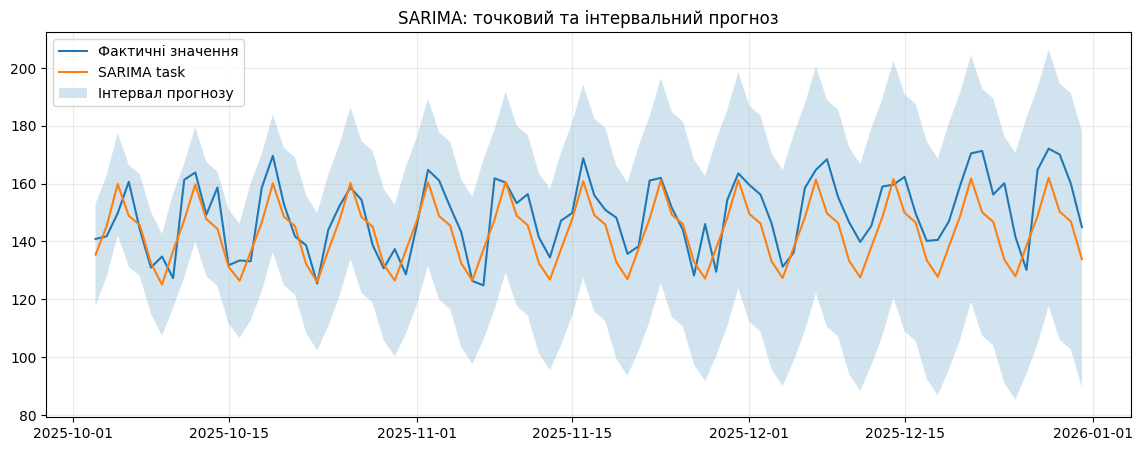

In [27]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, sarima_pred_task, label="SARIMA task")
ax.fill_between(
    test.index,
    sarima_ci_task.iloc[:, 0].values,
    sarima_ci_task.iloc[:, 1].values,
    alpha=0.2,
    label="Інтервал прогнозу"
)
ax.legend()
ax.set_title("SARIMA: точковий та інтервальний прогноз")
ax.grid(alpha=0.25)
plt.show()

In [28]:
results3 = pd.concat([results2,pd.DataFrame([sarima_metrics,sarima_metrics_task],index=["SARIMA","SARIMA task"])])
results3

,MAE,RMSE,sMAPE_%,MASE
Naive,22.039691,25.297086,15.570350,3.108885
Seasonal naive,7.734062,9.380056,5.276847,1.090955
ETS,13.114526,15.229021,9.149617,1.849915
ETS w/o trend,8.894899,10.703167,6.091459,1.254701
SARIMA,7.746566,9.401756,5.302246,1.092719
SARIMA task,8.092037,9.663575,5.528950,1.141450


## 11. Prophet

Prophet зручно використовувати для рядів з трендом, сезонністю та календарними ефектами.

У Prophet назви основних стовпців мають бути:

- `ds` — дата;
- `y` — цільове значення.

Якщо бібліотека не встановлена, у Google Colab її можна встановити командою:

```python
!pip -q install prophet
```

In [29]:
!pip -q install prophet

In [30]:
# Розкоментуйте, якщо Prophet встановлений.

from prophet import Prophet
prophet_train = (
    train.reset_index()
         .rename(columns={"date": "ds", "sales": "y"})
)
model_prophet = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive"
)
model_prophet.fit(prophet_train)
future = model_prophet.make_future_dataframe(
    periods=len(test),
    freq="D"
)
forecast = model_prophet.predict(future)
prophet_pred = (
    forecast.set_index("ds")
            .loc[test.index, "yhat"]
)
evaluate(
    test["sales"],
    prophet_pred,
    train["sales"],
    seasonality=7
)

{'MAE': 5.3019589947018195,
 'RMSE': np.float64(6.4375131479292),
 'sMAPE_%': np.float64(3.619983187399482),
 'MASE': np.float64(0.7478860972551259)}

### Завдання 9. Prophet

Після встановлення `prophet`:

1. навчіть модель;
2. отримайте прогноз на тестовий період;
3. побудуйте графік;
4. виведіть компоненти моделі;
5. порівняйте MAE з ETS та SARIMA.

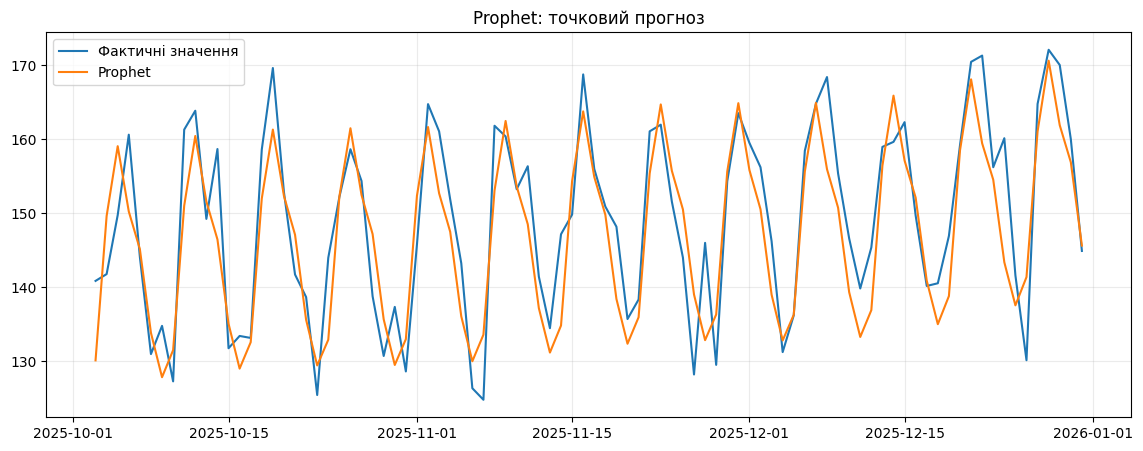

In [31]:
# Ваш код тут
model_prophet_task = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive"
)
model_prophet_task.fit(prophet_train)
forecast_task = model_prophet_task.predict(future)
prophet_pred_task = (
  forecast_task.set_index("ds")
          .loc[test.index, "yhat"]
)
fig, ax = plt.subplots(figsize=(14,5))
ax.plot(test.index,test["sales"].values,label="Фактичні значення")
ax.plot(prophet_pred.index,prophet_pred_task.values,label="Prophet")
ax.legend()
ax.set_title("Prophet: точковий прогноз")
ax.grid(alpha=0.25)
plt.show()

In [32]:
print("Prophet MAE:",mean_absolute_error(test["sales"].values,prophet_pred_task))
print("ETS MAE:",mean_absolute_error(test["sales"].values,ets_pred))
print("SARIMA MAE:",mean_absolute_error(test["sales"].values,sarima_pred))

Prophet MAE: 5.3019589947018195
ETS MAE: 13.11452610803631
SARIMA MAE: 7.7465658208202095


## 12. Ознаки для машинного навчання

Для використання класичних ML-моделей часовий ряд перетворюють на табличний набір ознак.

Типові ознаки:

- лаги;
- ковзні середні;
- день тижня;
- місяць;
- день року;
- ознака вихідного дня.

**Критичний момент:** ковзні характеристики мають обчислюватися тільки за минулими значеннями. Саме тому перед `rolling()` використовується `shift(1)`.

In [33]:
def make_features(series):
    data = pd.DataFrame({"y": series.copy()})

    for lag in [1, 2, 3, 7, 14, 28]:
        data[f"lag_{lag}"] = data["y"].shift(lag)

    data["roll_mean_7"] = data["y"].shift(1).rolling(7).mean()
    data["roll_mean_28"] = data["y"].shift(1).rolling(28).mean()
    data["roll_std_7"] = data["y"].shift(1).rolling(7).std()

    data["dayofweek"] = data.index.dayofweek
    data["month"] = data.index.month
    data["dayofyear"] = data.index.dayofyear
    data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

    return data

ml_df = make_features(df["sales"]).dropna()
ml_df.head()

,y,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_28,roll_std_7,dayofweek,month,dayofyear,is_weekend
date,,,,,,,,,,,,,,
2022-01-29,111.082231,97.400770,85.764899,99.669338,112.207900,102.048594,112.980285,104.512145,104.134824,11.932523,5,1,29,1
2022-01-30,122.474286,111.082231,97.400770,85.764899,123.513016,118.574712,118.725005,104.351335,104.067036,11.818566,6,1,30,1
2022-01-31,113.086640,122.474286,111.082231,97.400770,107.038953,108.356362,115.930451,104.202945,104.200939,11.541145,0,1,31,0
2022-02-01,121.472125,113.086640,122.474286,111.082231,105.990140,109.993414,114.862459,105.066901,104.099374,12.005835,1,2,32,0
2022-02-02,100.017166,121.472125,113.086640,122.474286,99.669338,92.413005,94.078518,107.278613,104.335434,13.533155,2,2,33,0


In [34]:
ml_train = ml_df.loc[ml_df.index < test.index.min()].copy()
ml_test = ml_df.loc[ml_df.index >= test.index.min()].copy()

X_train = ml_train.drop(columns="y")
y_train = ml_train["y"]

X_test = ml_test.drop(columns="y")
y_test = ml_test["y"]

gbr = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gbr.fit(X_train, y_train)
ml_pred = gbr.predict(X_test)

ml_metrics = evaluate(
    y_test,
    ml_pred,
    train["sales"],
    seasonality=7
)

ml_metrics

{'MAE': 6.4256724041518165,
 'RMSE': np.float64(7.708139982015866),
 'sMAPE_%': np.float64(4.411484230090363),
 'MASE': np.float64(0.9063953646912981)}

### Зауваження щодо попереднього прикладу

Цей приклад демонструє **табличне формування ознак** та оцінювання моделі. Для реального багатокрокового прогнозу потрібно чітко визначити, які ознаки будуть відомі у момент прогнозування.

Якщо для майбутніх дат лагова ознака використовує фактичне значення, яке на момент прогнозу ще невідоме, виникає **витік даних**.

Для багатокрокового прогнозування застосовують, зокрема:

- recursive strategy;
- direct strategy;
- multi-output strategy.

### Завдання 10. Feature engineering

Додайте щонайменше три нові ознаки:

- лаг 21;
- 14-денне ковзне середнє;
- номер тижня року.

Перенавчіть модель та порівняйте результат.

Після цього перевірте, чи всі створені ознаки могли бути відомими на момент формування прогнозу.

In [35]:
# Ваш код тут
ml_df_task = ml_df.copy()
ml_df_task["lag_21"] = ml_df_task["y"].shift(21)
ml_df_task["roll_mean_14"] = ml_df_task["y"].shift(1).rolling(14).mean()
ml_df_task["weekofyear"] = ml_df_task.index.to_period().weekofyear

In [36]:
ml_train_task = ml_df_task.loc[ml_df_task.index < test.index.min()].copy()
ml_test_task = ml_df_task.loc[ml_df_task.index >= test.index.min()].copy()

X_train_task = ml_train_task.drop(columns="y")
y_train_task = ml_train_task["y"]

X_test_task = ml_test_task.drop(columns="y")
y_test_task = ml_test_task["y"]

gbr_task = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gbr_task.fit(X_train_task,y_train_task)
ml_pred_task = gbr_task.predict(X_test_task)

ml_metrics_task = evaluate(
  y_test_task,
  ml_pred_task,
  train["sales"],
  seasonality=7
)

In [37]:
results4 = pd.concat([results3,pd.DataFrame([ml_metrics,ml_metrics_task],index=["ML","ML task"])])
results4

,MAE,RMSE,sMAPE_%,MASE
Naive,22.039691,25.297086,15.570350,3.108885
Seasonal naive,7.734062,9.380056,5.276847,1.090955
ETS,13.114526,15.229021,9.149617,1.849915
ETS w/o trend,8.894899,10.703167,6.091459,1.254701
SARIMA,7.746566,9.401756,5.302246,1.092719
SARIMA task,8.092037,9.663575,5.528950,1.141450
ML,6.425672,7.708140,4.411484,0.906395
ML task,6.099125,7.645649,4.178735,0.860333


## 13. Порівняння моделей

Зведемо результати моделей у єдину таблицю.

In [38]:
comparison = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7),
    "ETS": ets_metrics,
    "SARIMA": sarima_metrics,
    "ML": ml_metrics
}).T

comparison.sort_values("MAE")

,MAE,RMSE,sMAPE_%,MASE
ML,6.425672,7.708140,4.411484,0.906395
Seasonal naive,7.734062,9.380056,5.276847,1.090955
SARIMA,7.746566,9.401756,5.302246,1.092719
ETS,13.114526,15.229021,9.149617,1.849915
Naive,22.039691,25.297086,15.570350,3.108885


In [39]:
results4

,MAE,RMSE,sMAPE_%,MASE
Naive,22.039691,25.297086,15.570350,3.108885
Seasonal naive,7.734062,9.380056,5.276847,1.090955
ETS,13.114526,15.229021,9.149617,1.849915
ETS w/o trend,8.894899,10.703167,6.091459,1.254701
SARIMA,7.746566,9.401756,5.302246,1.092719
SARIMA task,8.092037,9.663575,5.528950,1.141450
ML,6.425672,7.708140,4.411484,0.906395
ML task,6.099125,7.645649,4.178735,0.860333


### Завдання 11. Порівняння

Дайте письмову відповідь у Markdown-комірці:

1. Яка модель показала найменший MAE?
2. Чи перевершує вона seasonal naive?
3. Чи однаковий висновок за MAE, RMSE, sMAPE та MASE?
4. Яку модель Ви обрали б для практичного використання і чому?

**Ваша відповідь:**

Найменший MAE показала модель ML з самостійного завдання зі значенням 6.1. Так, дана модель перевіршує Seasonal naive на 2.6 одиниць, ML модель також краща за Seaonal naive у інших метриках. При цьому, для практичного використання я обрав би модель SARIMA: вона показує майже рівні результати з Seasonal naive і не вимагає перетворення часового ряду у табличні дані.

## 14. Покрокова ретроспективна перевірка

Один train/test split може дати випадковий результат. Надійніший підхід — кілька разів імітувати ситуацію, коли модель навчається тільки на минулому та прогнозує наступний часовий відрізок.

Нижче реалізовано спрощений rolling-origin backtesting для seasonal naive.

In [40]:
def rolling_seasonal_naive_cv(series, initial=700, horizon=28, step=28, seasonality=7):
    rows = []

    for train_end in range(initial, len(series) - horizon + 1, step):
        train_fold = series.iloc[:train_end]
        test_fold = series.iloc[train_end:train_end + horizon]

        full = pd.concat([train_fold, test_fold])
        pred = full.shift(seasonality).loc[test_fold.index]

        rows.append({
            "train_end": train_fold.index.max(),
            "test_start": test_fold.index.min(),
            "test_end": test_fold.index.max(),
            "MAE": mean_absolute_error(test_fold, pred),
            "RMSE": rmse(test_fold, pred)
        })

    return pd.DataFrame(rows)

cv_results = rolling_seasonal_naive_cv(
    df["sales"],
    initial=700,
    horizon=28,
    step=28,
    seasonality=7
)

cv_results

,train_end,test_start,test_end,MAE,RMSE
0,2023-12-01,2023-12-02,2023-12-29,11.726037,22.703319
1,2023-12-29,2023-12-30,2024-01-26,6.347953,7.977381
2,2024-01-26,2024-01-27,2024-02-23,6.816896,7.867398
3,2024-02-23,2024-02-24,2024-03-22,5.245028,6.584598
4,2024-03-22,2024-03-23,2024-04-19,7.455005,9.252134
5,2024-04-19,2024-04-20,2024-05-17,6.096014,7.548739
6,2024-05-17,2024-05-18,2024-06-14,7.319789,9.073672
7,2024-06-14,2024-06-15,2024-07-12,6.137219,7.365825
8,2024-07-12,2024-07-13,2024-08-09,5.629306,6.705414
9,2024-08-09,2024-08-10,2024-09-06,6.042439,7.485644


In [41]:
cv_results[["MAE", "RMSE"]].agg(["mean", "std", "min", "max"])

,MAE,RMSE
mean,7.299416,9.797419
std,1.943769,5.694299
min,5.245028,6.584598
max,14.629295,34.184076


### Завдання 12. Backtesting

1. Змініть `horizon` з 28 на 14 днів.
2. Порівняйте середню MAE.
3. Побудуйте графік MAE для всіх fold.
4. Поясніть, що показує варіативність похибки між fold.

MAE horizon=28: 7.299416261220778
MAE horizon=14: 7.8077544473591045


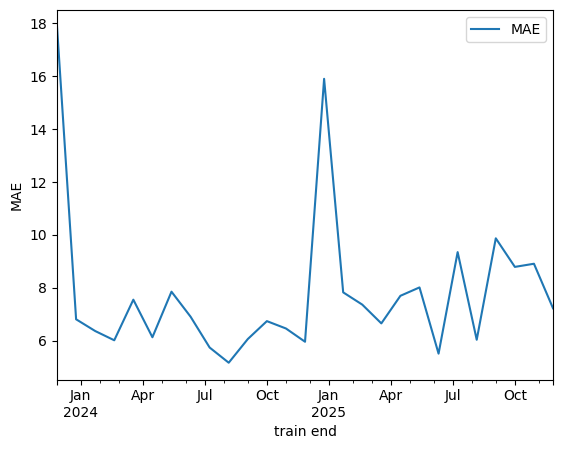

In [42]:
# Ваш код тут
cv_results_task = rolling_seasonal_naive_cv(
    df["sales"],
    initial=700,
    horizon=14,
    step=28,
    seasonality=7
)

print("MAE horizon=28:",cv_results["MAE"].mean())
print("MAE horizon=14:",cv_results_task["MAE"].mean())

cv_results_task[["train_end","MAE"]].plot(kind="line",x="train_end",y="MAE")
plt.xlabel("train end")
plt.ylabel("MAE")
plt.show()

Варіативність похибки між fold'ами показує, що існує залежність між періодом навчання та якістю моделі. Це означає, що для визначення справжньої якості моделі необхідно декілька train/test сплітів.

## 15. Додаткове завдання: прогнозні інтервали

Точковий прогноз показує одне найбільш очікуване значення. На практиці важливо також оцінювати невизначеність.

Використайте інтервал прогнозу SARIMA і визначте, яка частка фактичних значень тестової вибірки потрапила між нижньою та верхньою межами.

In [53]:
# Ваш код тут
print(
  "Між нижньою та верхньою межами потрапило: ",
  (
      (sarima_ci.iloc[:, 0].values > test["sales"].values)
    | (sarima_ci.iloc[:, 1].values < test["sales"].values)
  ).sum() / len(test),
  "%",
  sep=""
)

Між нижньою та верхньою межами потрапило: 0.03333333333333333%


## 16. Підсумкове практичне завдання

Виконайте повний цикл прогнозування самостійно.

### Умова

Використайте часовий ряд `df["sales"]`.

### Необхідно

1. Провести первинний аналіз.
2. Перевірити пропуски та регулярність часової шкали.
3. Побудувати графік ряду.
4. Виконати STL-декомпозицію.
5. Виділити останні 60 днів як test.
6. Побудувати seasonal naive.
7. Побудувати одну статистичну модель: ETS або SARIMA.
8. Побудувати одну ML-модель.
9. Обчислити MAE, RMSE, sMAPE і MASE.
10. Порівняти моделі.
11. Побудувати графік найкращого прогнозу.
12. Сформулювати короткий висновок.

### Висновок має містити

- яка модель є найкращою;
- наскільки вона перевершує baseline;
- які закономірності виявлено в ряді;
- які обмеження має отриманий прогноз.

In [44]:
# 1. Первинний аналіз
# Ваш код тут
print(df.shape)
print(df.dtypes)
print("\nКількість дуплікатів дат:")
print(df.index.duplicated().sum())
print("\nКількість дуплікатів продажів:")
print(df["sales"].duplicated().sum())

print("\nМінімальна дата:",df.index.min(),"Максимальна дата:",df.index.max())

print("\nСереднє:",df["sales"].mean())
print("Медіана:",df["sales"].median())
print("стандартне відхилення:",df["sales"].std())
print("мінімум:",df["sales"].min())
print("максимум:",df["sales"].max())

(1461, 1)
sales    float64
dtype: object

Кількість дуплікатів дат:
0

Кількість дуплікатів продажів:
0

Мінімальна дата: 2022-01-01 00:00:00 Максимальна дата: 2025-12-31 00:00:00

Середнє: 128.86642728935436
Медіана: 128.2968988071915
стандартне відхилення: 19.95085111462701
мінімум: 78.05403090053971
максимум: 279.5724799225864


In [45]:
# 2. Підготовка даних
# Ваш код тут
print("\nКількість пропусків:")
print(df["sales"].isna().sum())


Кількість пропусків:
0


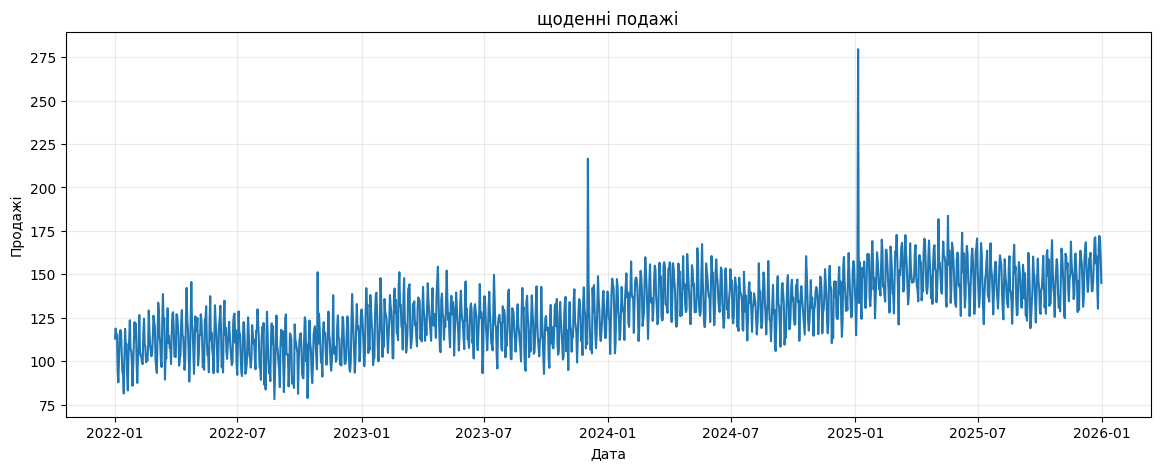

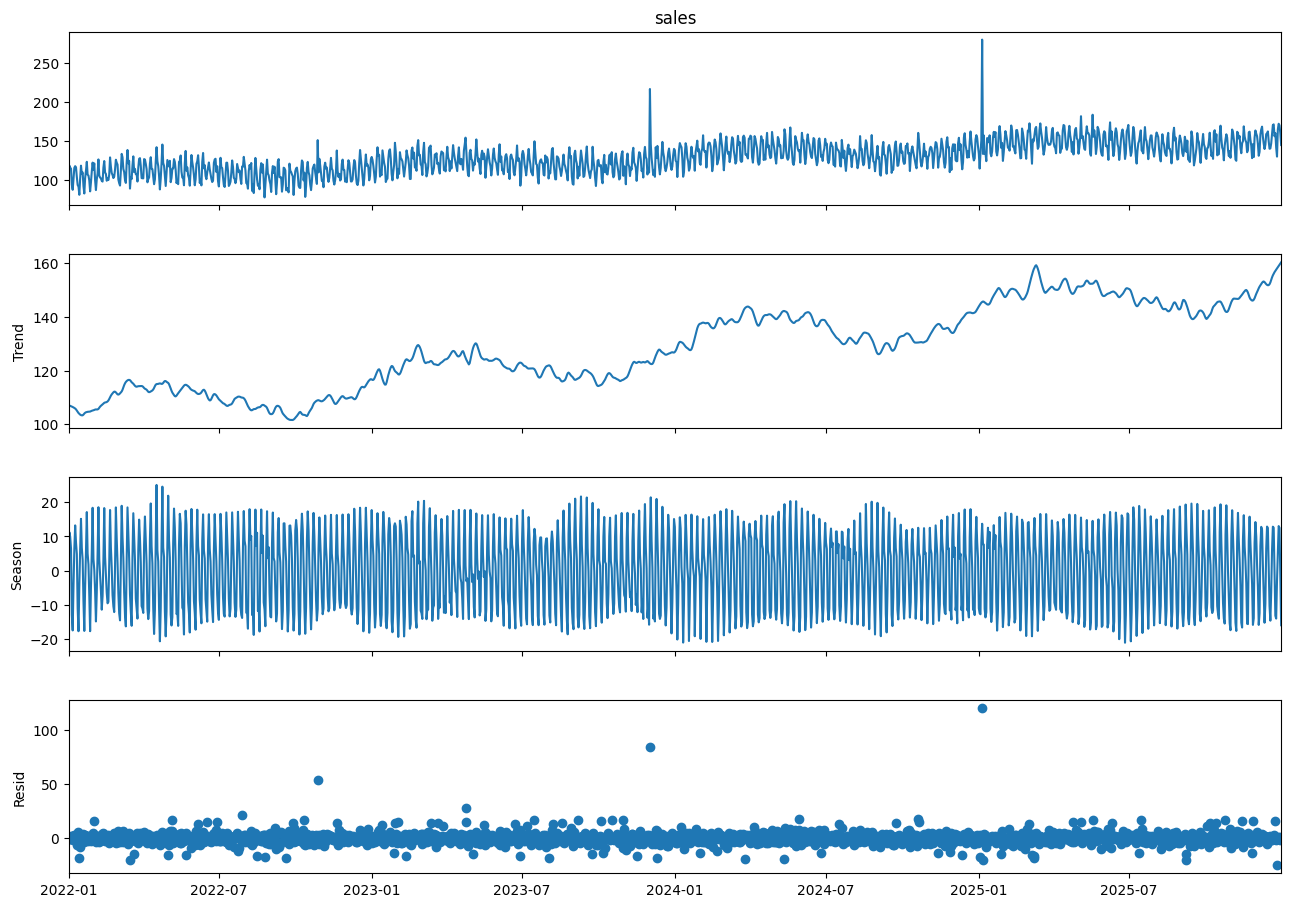

In [56]:
# 3. Візуалізація та STL
# Ваш код тут
fig, ax = plt.subplots(figsize=(14,5))
ax.plot(df.index,df["sales"])
ax.set_title("щоденні подажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.grid(alpha=0.25)
plt.show()

stl_result = STL(df["sales"],period=7,robust=True).fit()

fig = stl_result.plot()
fig.set_size_inches((14,10))
plt.show()

In [57]:
# 4. Train/test split
# Ваш код тут

horizon = 60

train = df.iloc[:-horizon].copy()
test = df.iloc[-horizon:].copy()

In [69]:
# 5. Seasonal naive baseline
# Ваш код тут
history = pd.concat([train["sales"], test["sales"]])
seasonal_naive_pred = history.shift(7).loc[test.index].values

In [59]:
# 6. Статистична модель
# Ваш код тут
sarima_model = SARIMAX(
    train["sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_forecast = sarima_model.get_forecast(steps=len(test))
sarima_pred = sarima_forecast.predicted_mean
sarima_ci = sarima_forecast.conf_int()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [65]:
# 7. ML-модель
# Ваш код тут
ml_df = pd.DataFrame()

ml_df["y"] = df["sales"].copy()

ml_df["roll_mean_7"] = ml_df["y"].shift(1).rolling(7).mean()
ml_df["roll_mean_30"] = ml_df["y"].shift(1).rolling(30).mean()
ml_df["roll_mean_355"] = ml_df["y"].shift(1).rolling(355).mean()
ml_df["roll_std_7"] = ml_df["y"].shift(1).rolling(7).std()

ml_df["dayofweek"] = ml_df.index.dayofweek
ml_df["month"] = ml_df.index.month
ml_df["dayofyear"] = ml_df.index.dayofyear
ml_df["is_weekend"] = (ml_df.index.dayofweek >= 5).astype(int)

ml_train = ml_df.loc[ml_df.index < test.index.min()].copy()
ml_test = ml_df.loc[ml_df.index >= test.index.min()].copy()

X_train = ml_train.drop(columns="y")
y_train = ml_train["y"]

X_test = ml_test.drop(columns="y")
y_test = ml_test["y"]

gbr = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
).fit(X_train,y_train)

ml_pred = gbr.predict(X_test)

In [71]:
# 8. Порівняння метрик
# Ваш код тут
metrics = {
  "baseline": evaluate(test["sales"],seasonal_naive_pred,train["sales"],seasonality=7),
  "SARIMAX": evaluate(test["sales"],sarima_pred,train["sales"],seasonality=7),
  "ML_GBR": evaluate(y_test,ml_pred,y_train,seasonality=7),
}

metrics_df = pd.DataFrame(metrics).T
metrics_df

,MAE,RMSE,sMAPE_%,MASE
baseline,7.523370,9.241039,5.107073,1.057811
SARIMAX,8.254891,9.780364,5.602010,1.160666
ML_GBR,5.933777,7.343163,3.982895,0.834309


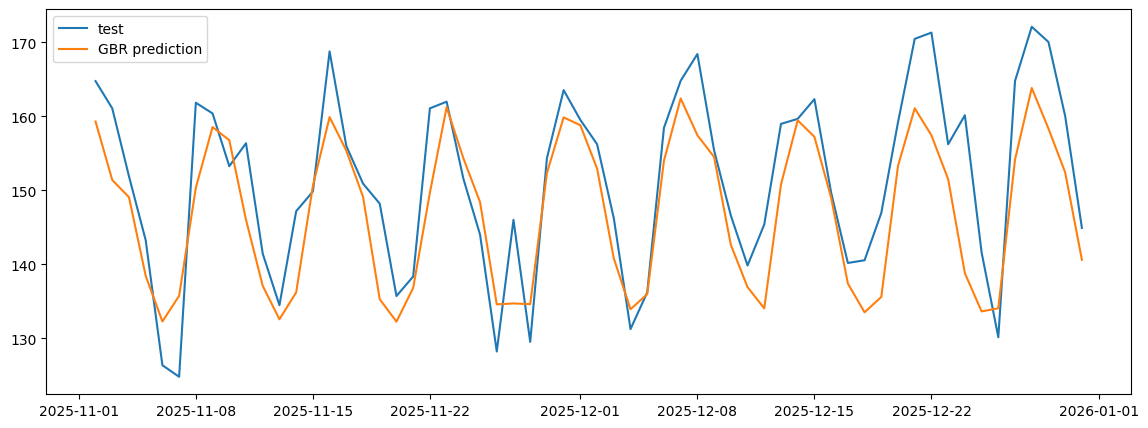

In [75]:
# 9. Фінальний графік
# Ваш код тут
fig, ax = plt.subplots(figsize=(14,5))
ax.plot(test.index,test["sales"],label="test")
ax.plot(test.index,ml_pred,label="GBR prediction")
ax.legend()
plt.show()

### Підсумковий висновок

Напишіть 5–8 речень академічним стилем.

**Ваша відповідь:**

У цьому практичному завдані було виявлено, що найкращою моделю для прогнозування данного часового ряду є модель машинного навчання Gradient Boosting Regressor. Дана модель має кращі показники ніж інші моделі у всіх чотирьох використаних метриках, перевершуючи baseline та SARIMAX на прибизно 15%. Але, найкращий прогноз також має обмеження: як видно з фінального графіку, модель машинного навчання має проблему скорочування піків продажів у часі. При цьому, під час виконання завдання було виявлено наступні закономірності значень продажів: впродовж всього часового ряду існує тенденція зросту продажів, продажі також зростають над відносним середнім значенням по вихідних днях.

## 17. Контрольні запитання

1. Чому не можна випадково перемішувати часовий ряд перед train/test split?
2. Для чого потрібна базова модель?
3. Чим naive відрізняється від seasonal naive?
4. Що показує MAE?
5. Чому MAPE може бути проблемною за наявності нульових значень?
6. Що означає параметр сезонності `s` у SARIMA?
7. Навіщо використовувати `shift(1)` перед обчисленням rolling-ознак?
8. Що таке витік даних у часових рядах?
9. Навіщо потрібен rolling-origin backtesting?
10. Чому найскладніша модель не обов'язково дає найкращий прогноз?